# ESM3Di embeddings on viral polyprotein cleavage sites

**Question:** Do ESM3Di representations improve prediction of ICTV-annotated cleavage sites over frozen, stock ESM++ representations on a task beyond 3Di prediction?

This is a paired leave-one-group-out comparison across Hepacivirus, Orthoflavivirus, Pegivirus, and Pestivirus. Each outer fold trains the same FFN and sequence Transformer on the other three groups. Both embedding sources use the same sequences, tokenizer, windows, labels, folds, heads, and fixed hyperparameters. Unannotated proteins are excluded. For tractable full-length training, the Transformer head sees 512-residue chunks with a 64-residue overlap; overlap tokens provide context but contribute to the loss only once.

The ESM3Di features come from `checkpoints/esm3di_from_mlm/epoch_5.pt`. Despite its historical name, this is the 3Di-trained checkpoint and was **not** initialized from the MLM fine-tuning run. The baseline is stock `Synthyra/ESMplusplus_small` at revision `46c5f7d`.

The main scores are strict residue-level AP and AP after expanding positive labels by ±2/±5 residues. Top-10 site recovery uses non-maximum suppression and one-to-one matching within ±5 residues. A single fixed classifier seed (17) is used per table row to keep the CPU run practical.


In [1]:
from pathlib import Path
import os
import subprocess
import sys

repo_root = Path.cwd()
if not (repo_root / "experiments/analyses/polyprotein_cut/run_comparison.py").is_file():
    repo_root = (repo_root / "../../../").resolve()
script = repo_root / "experiments/analyses/polyprotein_cut/run_comparison.py"
output_dir = repo_root / "experiments/analyses/polyprotein_cut/results/esm3di_vs_esmpp"
cache_dir = Path("/tmp/polyprotein_cut_esm3di_vs_esmpp")
summary_path = output_dir / "summary.csv"
prediction_path = output_dir / "oof_ffn_predictions.csv"

if not summary_path.is_file() or not prediction_path.is_file():
    env = os.environ.copy()
    env["PYTHONPATH"] = str(repo_root / "src") + os.pathsep + env.get("PYTHONPATH", "")
    run = subprocess.run(
        [sys.executable, str(script), "--cache-dir", str(cache_dir), "--output-dir", str(output_dir)],
        cwd=repo_root, env=env, text=True, capture_output=True, check=True,
    )
    print("Experiment completed. Final output:")
    print("\n".join(run.stdout.splitlines()[-22:]))
else:
    print(f"Found completed results and FFN prediction scores at {output_dir}. Delete summary.csv and seed_metrics.partial.csv to rerun training; cached embeddings are in {cache_dir}.")


Found completed results and FFN prediction scores at /home/dmoi/projects/ESM3di/experiments/analyses/polyprotein_cut/results/esm3di_vs_esmpp. Delete summary.csv and seed_metrics.partial.csv to rerun training; cached embeddings are in /tmp/polyprotein_cut_esm3di_vs_esmpp.


In [2]:
import pandas as pd
from IPython.display import display

summary = pd.read_csv(summary_path)
metric_names = ["roc_auc", "ap_strict", "ap_tolerance_2", "ap_tolerance_5", "top10_site_recovery"]
rows = []
for (group, architecture), frame in summary.groupby(["heldout_group", "architecture"]):
    paired = frame.set_index("embedding_source")
    row = {"heldout_group": group, "architecture": architecture}
    for metric in metric_names:
        row[f"ESM3Di {metric}"] = paired.loc["esm3di", f"{metric}_mean"]
        row[f"ESM++ {metric}"] = paired.loc["esmpp_base", f"{metric}_mean"]
        row[f"difference {metric}"] = row[f"ESM3Di {metric}"] - row[f"ESM++ {metric}"]
    row["test sequences"] = int(paired.loc["esm3di", "n_test_sequences"])
    row["test cut sites"] = int(paired.loc["esm3di", "n_test_positives"])
    rows.append(row)
comparison = pd.DataFrame(rows).sort_values(["architecture", "heldout_group"])
display(comparison.round(4))


,heldout_group,architecture,ESM3Di roc_auc,ESM++ roc_auc,difference roc_auc,ESM3Di ap_strict,ESM++ ap_strict,difference ap_strict,ESM3Di ap_tolerance_2,ESM++ ap_tolerance_2,difference ap_tolerance_2,ESM3Di ap_tolerance_5,ESM++ ap_tolerance_5,difference ap_tolerance_5,ESM3Di top10_site_recovery,ESM++ top10_site_recovery,difference top10_site_recovery,test sequences,test cut sites
0,Hepacivirus-CHH,ffn,0.8584,0.8565,0.0019,0.0470,0.0409,0.0062,0.1012,0.0948,0.0064,0.1259,0.1148,0.0111,0.2830,0.2289,0.0541,15,148
2,Orthoflavivirus-CHH,ffn,0.8937,0.8885,0.0052,0.1655,0.1613,0.0042,0.1755,0.1355,0.0400,0.2059,0.1522,0.0537,0.2902,0.2887,0.0015,31,347
4,Pegivirus-CHH,ffn,0.8488,0.8074,0.0414,0.0519,0.0402,0.0117,0.0697,0.0695,0.0002,0.0872,0.0852,0.0020,0.3995,0.3142,0.0853,21,112
6,Pestivirus-CHH,ffn,0.8791,0.8591,0.0200,0.1991,0.2483,-0.0492,0.1727,0.1687,0.0040,0.1670,0.1475,0.0196,0.3928,0.3632,0.0297,19,193
1,Hepacivirus-CHH,transformer,0.7588,0.7808,-0.0220,0.0084,0.0279,-0.0194,0.0366,0.0932,-0.0566,0.0703,0.1144,-0.0441,0.0481,0.2356,-0.1874,15,148
3,Orthoflavivirus-CHH,transformer,0.8687,0.8919,-0.0233,0.0733,0.0914,-0.0180,0.1243,0.1141,0.0101,0.1639,0.1416,0.0223,0.2516,0.2348,0.0168,31,347
5,Pegivirus-CHH,transformer,0.8541,0.7808,0.0733,0.0459,0.0122,0.0337,0.0533,0.0302,0.0231,0.0670,0.0455,0.0216,0.2401,0.1548,0.0853,21,112
7,Pestivirus-CHH,transformer,0.6532,0.4954,0.1578,0.0143,0.0024,0.0119,0.0412,0.0125,0.0286,0.0527,0.0301,0.0226,0.1397,0.0053,0.1344,19,193


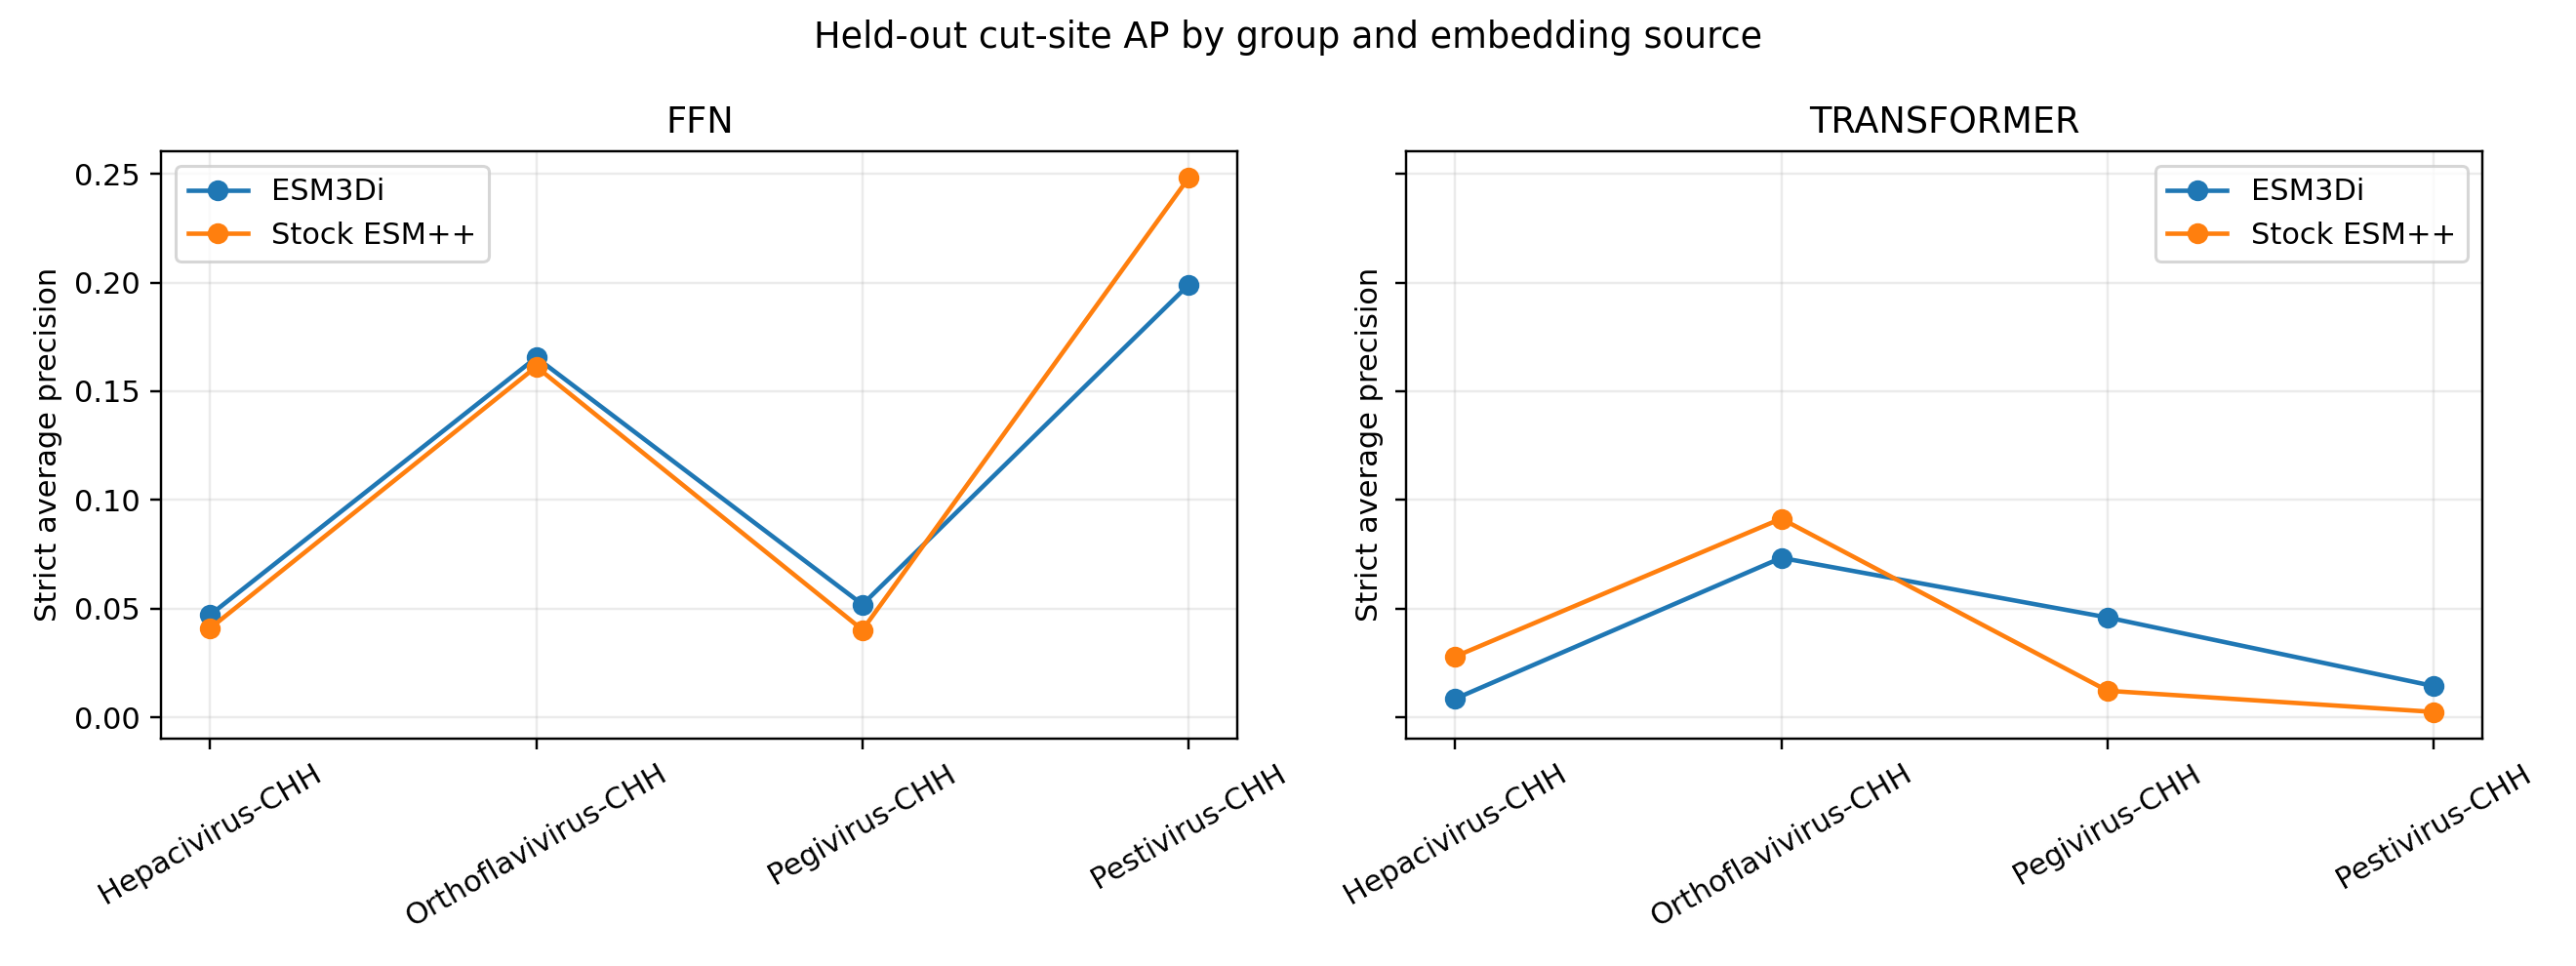

In [3]:
from IPython.display import Image, display

display(Image(filename=str(output_dir / "figure2_ap_by_group.png")))


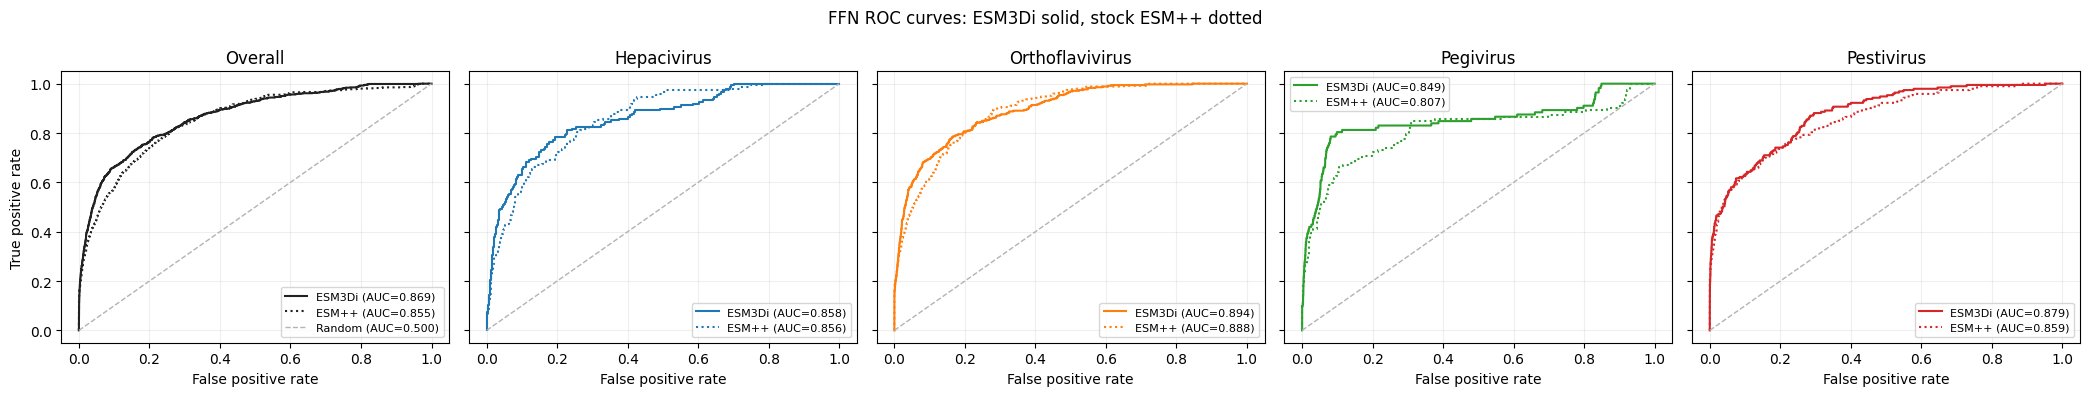

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import auc, roc_curve

roc_data = pd.read_csv(prediction_path)
groups = sorted(roc_data["heldout_group"].unique())
colors = dict(zip(groups, plt.get_cmap("tab10").colors))
fig, axes = plt.subplots(1, 1 + len(groups), figsize=(21, 4), sharex=True, sharey=True)

for source, color, style, label in (
    ("esm3di", "#222222", "-", "ESM3Di"),
    ("esmpp_base", "#222222", ":", "ESM++"),
):
    subset = roc_data[roc_data["embedding_source"] == source]
    fpr, tpr, _ = roc_curve(subset["label"], subset["score"])
    axes[0].plot(fpr, tpr, color=color, linestyle=style,
                 label=f"{label} (AUC={auc(fpr, tpr):.3f})")
axes[0].set_title("Overall")

for ax, group in zip(axes[1:], groups):
    subset = roc_data[roc_data["heldout_group"] == group]
    for source, style, label in (
        ("esm3di", "-", "ESM3Di"),
        ("esmpp_base", ":", "ESM++"),
    ):
        paired = subset[subset["embedding_source"] == source]
        fpr, tpr, _ = roc_curve(paired["label"], paired["score"])
        ax.plot(fpr, tpr, color=colors[group], linestyle=style,
                label=f"{label} (AUC={auc(fpr, tpr):.3f})")
    ax.set_title(group.replace("-CHH", ""))
    ax.legend(fontsize=8)

for ax in axes:
    ax.plot([0, 1], [0, 1], color="0.7", linewidth=1, linestyle="--", label="Random (AUC=0.500)")
    ax.set_xlabel("False positive rate")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("True positive rate")
axes[0].legend(fontsize=8)
fig.suptitle("FFN ROC curves: ESM3Di solid, stock ESM++ dotted")
fig.tight_layout()
fig.savefig(output_dir / "figure3_ffn_roc_curves.png", dpi=220)
display(fig)
plt.close(fig)


## Tolerant FFN curves and site recovery

The FFN curves below expand each annotated cleavage site within its own protein. Colors identify held-out clades; ESM3Di is solid and stock ESM++ is dotted.

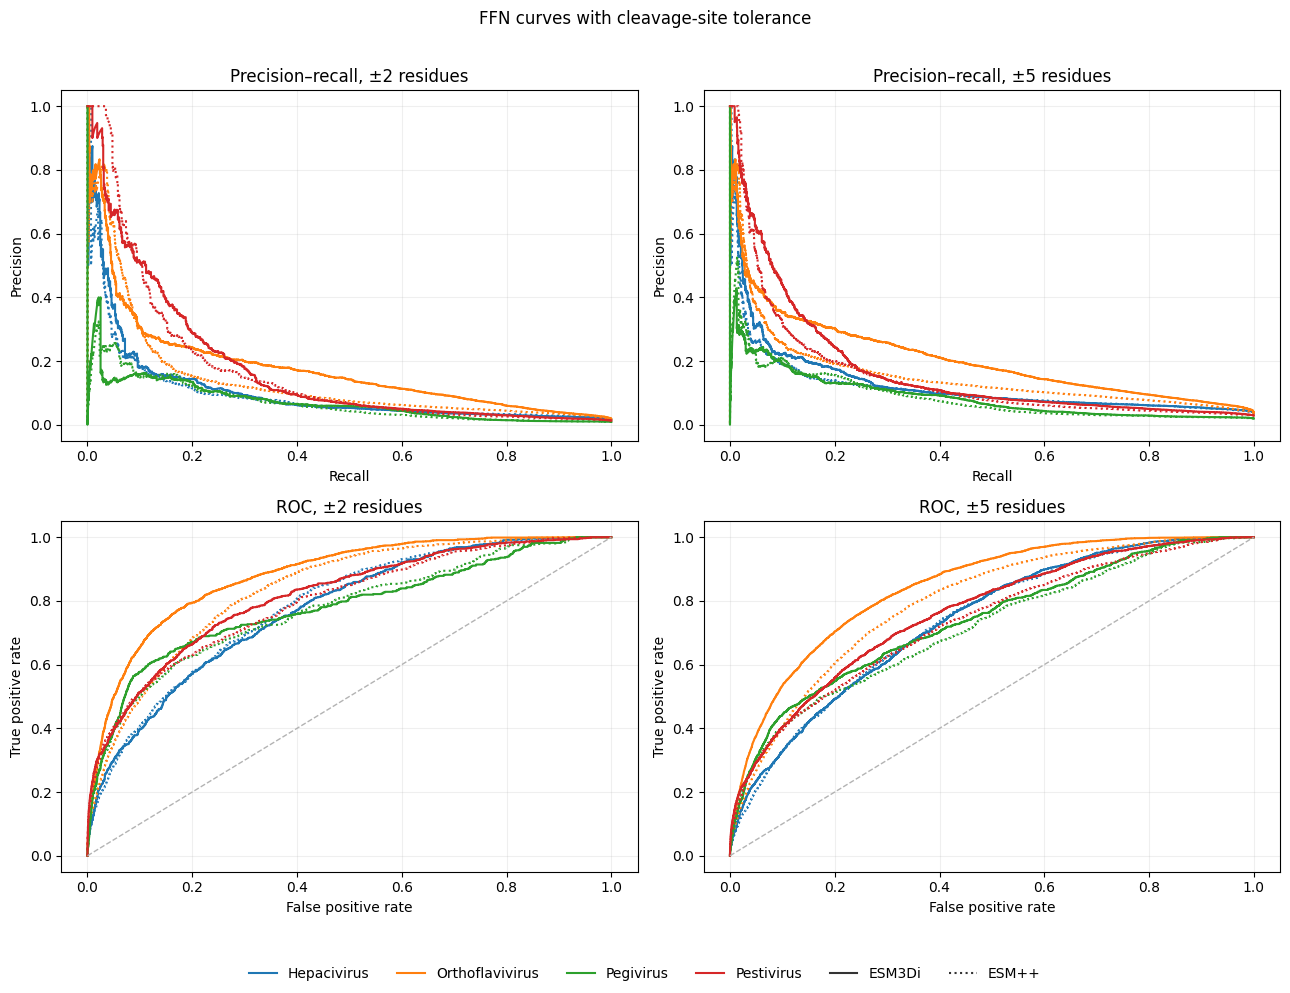

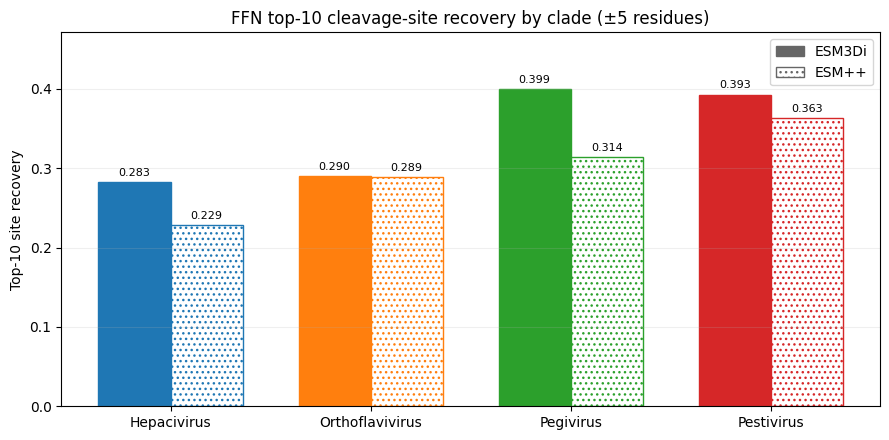

In [5]:
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.metrics import auc, precision_recall_curve, roc_curve


def add_tolerant_labels(frame, radius):
    """Expand positives within each protein, without crossing sequence boundaries."""
    frame = frame.copy()
    tolerant = np.zeros(len(frame), dtype=np.uint8)
    for positions in frame.groupby("sequence_id", sort=False).indices.values():
        labels = frame.iloc[positions]["label"].to_numpy(dtype=np.uint8)
        expanded = np.convolve(labels, np.ones(2 * radius + 1, dtype=np.uint8), mode="same") > 0
        tolerant[np.asarray(positions)] = expanded
    frame[f"label_tolerance_{radius}"] = tolerant
    return frame


tolerant_data = pd.concat(
    [add_tolerant_labels(frame, 5) for _, frame in roc_data.groupby("embedding_source", sort=False)],
    ignore_index=True,
)
for radius in (2,):
    labels = pd.concat(
        [add_tolerant_labels(frame, radius) for _, frame in roc_data.groupby("embedding_source", sort=False)],
        ignore_index=True,
    )
    tolerant_data[f"label_tolerance_{radius}"] = labels[f"label_tolerance_{radius}"]

source_styles = {"esm3di": ("-", "ESM3Di"), "esmpp_base": (":", "ESM++")}
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for column, radius in enumerate((2, 5)):
    label_column = f"label_tolerance_{radius}"
    for group in groups:
        group_data = tolerant_data[tolerant_data["heldout_group"] == group]
        for source, (style, model_label) in source_styles.items():
            paired = group_data[group_data["embedding_source"] == source]
            precision, recall, _ = precision_recall_curve(paired[label_column], paired["score"])
            fpr, tpr, _ = roc_curve(paired[label_column], paired["score"])
            short_group = group.replace("-CHH", "")
            axes[0, column].plot(
                recall, precision, color=colors[group], linestyle=style,
                label=f"{short_group} {model_label} (PR AUC={auc(recall, precision):.3f})",
            )
            axes[1, column].plot(
                fpr, tpr, color=colors[group], linestyle=style,
                label=f"{short_group} {model_label} (AUC={auc(fpr, tpr):.3f})",
            )
    axes[0, column].set_title(f"Precision–recall, ±{radius} residues")
    axes[0, column].set_xlabel("Recall")
    axes[0, column].set_ylabel("Precision")
    axes[1, column].set_title(f"ROC, ±{radius} residues")
    axes[1, column].set_xlabel("False positive rate")
    axes[1, column].set_ylabel("True positive rate")
    axes[1, column].plot([0, 1], [0, 1], color="0.7", linewidth=1, linestyle="--")
    for row in range(2):
        axes[row, column].grid(alpha=0.2)

legend_handles = [
    Line2D([0], [0], color=colors[group], label=group.replace("-CHH", "")) for group in groups
] + [
    Line2D([0], [0], color="0.2", linestyle=style, label=label)
    for style, label in source_styles.values()
]
fig.legend(handles=legend_handles, loc="lower center", ncol=6, frameon=False)
fig.suptitle("FFN curves with cleavage-site tolerance")
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(output_dir / "figure4_ffn_tolerant_pr_roc.png", dpi=220)
display(fig)
plt.close(fig)

top10 = (
    summary[summary["architecture"] == "ffn"]
    .pivot(index="heldout_group", columns="embedding_source", values="top10_site_recovery_mean")
    .reindex(groups)
)
x = np.arange(len(groups))
width = 0.36
fig, ax = plt.subplots(figsize=(9, 4.5))
for offset, source in ((-width / 2, "esm3di"), (width / 2, "esmpp_base")):
    style, model_label = source_styles[source]
    bars = ax.bar(
        x + offset, top10[source], width,
        color=[colors[group] if source == "esm3di" else "white" for group in groups],
        edgecolor=[colors[group] for group in groups],
        hatch=None if source == "esm3di" else "...",
        label=model_label,
    )
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
ax.set_xticks(x, [group.replace("-CHH", "") for group in groups])
ax.set_ylabel("Top-10 site recovery")
ax.set_ylim(0, max(top10.max()) * 1.18)
ax.set_title("FFN top-10 cleavage-site recovery by clade (±5 residues)")
ax.grid(axis="y", alpha=0.2)
ax.legend(handles=[
    Patch(facecolor="0.4", edgecolor="0.4", label="ESM3Di"),
    Patch(facecolor="white", edgecolor="0.4", hatch="...", label="ESM++"),
])
fig.tight_layout()
fig.savefig(output_dir / "figure5_ffn_top10_by_clade.png", dpi=220)
display(fig)
plt.close(fig)


## Metric definitions and interpretation

- `AP strict` treats only the annotated residue as positive.
- `AP ±2` and `AP ±5` expand each positive label by that many residues before calculating residue-level AP; overlapping windows around nearby sites merge.
- `Top-10 site recovery` is the macro-average per-protein fraction of annotated sites recovered among the ten highest-scoring, non-maximum-suppressed positions, matching each prediction to at most one site within ±5 residues.
- The summary table reports one paired run using fixed seed 17; seed variability is not estimated. `seed_metrics.csv` retains the run values and `run_metadata.json` records the checkpoint hash and settings.

The four groups are the outer test folds. No hyperparameters are selected on an outer test group. If stock ESM++ matches ESM3Di, that does not support an advantage from 3Di fine-tuning on this task.
